# Sprint 2 – Notebook 10: Hypothesis Testing

# 1. Introduction to Hypothesis Testing

What is Hypothesis Testing?

Hypothesis testing is a statistical method used to make decisions or draw conclusions about a population using sample data.

It helps us determine whether the observed results provide enough statistical evidence to support a claim or whether they may have occurred due to random variation.

Why is Hypothesis Testing important?

- Helps make decisions using data.
- Helps test assumptions.
- Helps compare groups.
- Helps evaluate claims.
- Helps in research and Machine Learning experiments.

Real-world example

Suppose a college claims that the average student mark is 60.

We collect marks from a sample of students and test whether the average mark is significantly different from 60.
AI/ML relevance

Hypothesis testing is useful in:
- Comparing Machine Learning models.
- Evaluating experiments.
- Testing feature relationships.
- Analyzing model performance.
- A/B testing.

# 2. Null Hypothesis (H₀)

The Null Hypothesis is a statement that assumes there is no significant difference, no effect or no relationship, depending on the statistical test.

It represents the default assumption that we test using sample data.

# 3. Alternative Hypothesis (H₁)

The Alternative Hypothesis is a statement that indicates a difference, effect or relationship exists.

It is considered when the sample data provides sufficient evidence against the Null Hypothesis.

Example

If we want to test whether the average student mark is different from 60:
\[
H_1:\mu\neq60
\]

Interpretation

The alternative hypothesis states that the population mean is not equal to 60.
Null vs Alternative Hypothesis
Null Hypothesis (H₀)	Alternative Hypothesis (H₁)
Assumes no difference or effect as specified by the test	Indicates a difference or effect
Default assumption	Competing statement
Evaluated using statistical evidence	Supported when H₀ is rejected


# 4. Significance Level (α)

What is Significance Level?

The significance level is the threshold used to decide whether the statistical evidence is strong enough to reject the Null Hypothesis.

It is represented by alpha (\(\alpha\)).

A common significance level is:
\[
\alpha=0.05
\]

This means we accept a 5% risk of rejecting a true Null Hypothesis when using this decision rule.

Common Significance Levels

Significance Level	Meaning

0.01	1% significance level
0.05	5% significance level
0.10	10% significance level

Example

If we choose \(\alpha=0.05\), we compare the p-value with 0.05.
- If p-value < 0.05, reject H₀.
- If p-value ≥ 0.05, fail to reject H₀.

Interpretation

The significance level is selected before performing the test. It defines the threshold for statistical evidence.

# 5. p-value

What is a p-value?

The p-value is the probability, assuming the Null Hypothesis is true, of obtaining a result at least as extreme as the one observed under the statistical test.

Decision Rule

p-value	Decision
p-value < α	Reject Null Hypothesis
p-value ≥ α	Fail to reject Null Hypothesis

Example
Suppose:
- Significance Level = 0.05
- p-value = 0.03
Since:
\[
0.03<0.05
\]

We reject the Null Hypothesis.

Interpretation
The observed result provides statistically significant evidence against the Null Hypothesis at the 5% significance level.

Important: The p-value is not the probability that the Null Hypothesis is true.

# 6. Confidence Interval

What is a Confidence Interval?

A confidence interval is a range of values calculated from sample data that is used to estimate an unknown population parameter.

A 95% confidence interval is produced by a procedure that, over repeated samples under the same assumptions, would contain the true population parameter approximately 95% of the time.

Formula (when population standard deviation is known and normal assumptions apply)
\[
CI=\bar X\pm Z_{\alpha/2}\frac{\sigma}{\sqrt n}
\]

Where:
- \(\bar X\) = Sample mean
- \(Z_{\alpha/2}\) = Critical Z-value
- \(\sigma\) = Population standard deviation
- \(n\) = Sample size

Common Confidence Levels
Confidence Level	Critical Z-Value (approx.)
90%	1.645
95%	1.96
99%	2.576

Interpretation

A confidence interval provides a range of plausible values for the population mean based on the sample and the assumptions of the method.

Python Implementation

We will calculate a 95% confidence interval for our student marks using the t-distribution because the population standard deviation is unknown.

In [1]:
import numpy as np
from scipy import stats

marks = np.array([55, 58, 62, 65, 60, 57, 64, 59, 63, 61])

mean = np.mean(marks)
std = np.std(marks, ddof=1)
n = len(marks)

confidence_level = 0.95

t_critical = stats.t.ppf(
    (1 + confidence_level) / 2,
    df=n - 1
)

margin_of_error = t_critical * std / np.sqrt(n)

lower_limit = mean - margin_of_error
upper_limit = mean + margin_of_error

print("Mean:", mean)
print("95% Confidence Interval:", (lower_limit, upper_limit))

Mean: 60.4
95% Confidence Interval: (np.float64(58.107879185069535), np.float64(62.69212081493046))


# 7. Type I Error

A Type I Error occurs when we reject a true Null Hypothesis.

It means we conclude that a significant difference or effect exists when it actually does not, according to the Null Hypothesis.

Example

Suppose the true average mark of students is 60.

We test the Null Hypothesis that the average mark is 60.

If our test rejects the Null Hypothesis even though it is true, we make a Type I Error.

Type I Error = False Positive

# 8. Type II Error

A Type II Error occurs when we fail to reject a false Null Hypothesis.

It means we fail to detect a real difference or effect.

Example

Suppose the true average mark is actually 65, but our test fails to reject the Null Hypothesis that the average mark is 60.

This is a Type II Error.

Type II Error = False Negative

# 9. One-Tailed Test

What is a One-Tailed Test?

A One-Tailed Test evaluates whether a population parameter differs from a reference value in a specific direction.

It can test whether a parameter is greater than or less than a reference value.

Types

Right-tailed test
Left-tailed test

# 10. Two-Tailed Test

What is a Two-Tailed Test?

A Two-Tailed Test evaluates whether a population parameter is different from a reference value in either direction.

It tests for both greater-than and less-than differences.

# 11. Practical Hypothesis Testing Using Student Marks

Objective

We want to test whether the average marks of students are significantly different from 60.
Dataset

In [2]:
marks = [55, 58, 62, 65, 60, 57, 64, 59, 63, 61]

Step 1: Define Hypotheses

Null Hypothesis (H₀):
\[
H_0:\mu=60
\]

Alternative Hypothesis (H₁):
\[
H_1:\mu\neq60
\]

Step 2: Set Significance Level

In [3]:
alpha = 0.05

We use a 5% significance level.

Step 3: Calculate Sample Mean

In [4]:
import numpy as np

marks = np.array([55, 58, 62, 65, 60, 57, 64, 59, 63, 61])

sample_mean = np.mean(marks)

print("Sample Mean:", sample_mean)

Sample Mean: 60.4


# 12. Perform One-Sample T-Test

What is a One-Sample T-Test?

A One-Sample T-Test is a statistical test used to determine whether the sample mean is significantly different from a specified population mean.

It is commonly used when the population standard deviation is unknown.

In [5]:
from scipy import stats

t_statistic, p_value = stats.ttest_1samp(
    marks,
    popmean=60
)

print("T-Statistic:", t_statistic)
print("P-Value:", p_value)

T-Statistic: 0.39477101697586
P-Value: 0.7022041268375009


# 13. Make a Decision

In [6]:
if p_value < alpha:
    print("Reject the Null Hypothesis")
else:
    print("Fail to Reject the Null Hypothesis")

Fail to Reject the Null Hypothesis


# 14. Visualize the Student Marks

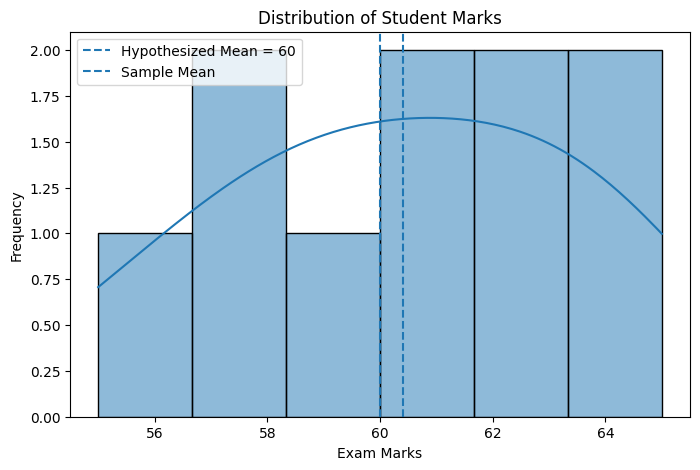

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(marks, bins=6, kde=True)

plt.axvline(
    60,
    linestyle="--",
    label="Hypothesized Mean = 60"
)

plt.axvline(
    np.mean(marks),
    linestyle="--",
    label="Sample Mean"
)

plt.xlabel("Exam Marks")
plt.ylabel("Frequency")
plt.title("Distribution of Student Marks")

plt.legend()

plt.show()

Interpretation

- The histogram shows the distribution of marks.
- The first vertical line represents the hypothesized mean of 60.
- The second vertical line represents the sample mean of 60.4.
- The sample mean is close to the hypothesized mean.

The visualization helps us understand the sample data, but the statistical test is used to evaluate the hypothesis.

# 15. Hypothesis Testing in AI/ML

Hypothesis testing is used in Machine Learning and Data Science to evaluate assumptions and compare results.
Applications

- Model Comparison: Evaluating whether the performance of two models differs significantly.
- Feature Analysis: Testing whether a feature is associated with an outcome.
- Experimentation: Evaluating the results of A/B tests.
- Data Analysis: Testing claims about data.
- Decision Making: Making decisions based on statistical evidence.

Example

Suppose we train two Machine Learning models to predict student marks.

We can use statistical methods to investigate whether their performance differences are statistically significant.

However, the appropriate test depends on the experimental design, metric, data and assumptions. Statistical significance alone does not mean a model is practically better.

# 16. Advantages of Hypothesis Testing
1. Helps make data-driven decisions.
2. Provides a systematic method for testing claims.
3. Helps evaluate statistical significance.
4. Useful for comparing groups.
5. Helps analyze experiments.
6. Useful in Data Science and Machine Learning.

# 17. Limitations of Hypothesis Testing
1. Results depend on assumptions.
2. A p-value does not measure the size or importance of an effect.
3. Statistical significance does not always mean practical significance.
4. Small sample sizes may reduce statistical power.
5. Incorrect data can produce misleading results.
6. Failing to reject H₀ does not prove H₀ is true.